<a href="https://colab.research.google.com/github/SilviaVenturini/bitcoin-sentiment-analysis-pyspark/blob/main/Bitcoin_Sentiment_Analysis_Based_on_Tweets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# PySpark installation.
!pip install -q pyspark
!pip install -q langdetect # Language detection library.

# Libraries.
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from scipy.stats import pearsonr
from langdetect import detect

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates
import seaborn as sns
import requests
import nltk

# Initialize PySpark session.
spark = (SparkSession.builder.appName("BitcoinSentimentAnalysis").getOrCreate())

In [ ]:
# Importing the dataset.
URL = "https://proai-datasets.s3.eu-west-3.amazonaws.com/bitcoin_tweets.csv"

# HTTP GET request to the specified URL.
response = requests.get(URL)
response.raise_for_status()

with open("/tmp/bitcoin_tweets.csv", "wb") as f:

    # Writes the content received from the server to the file.
    f.write(response.content)

# Read dataset.
df = spark.read.csv(
    "file:///tmp/bitcoin_tweets.csv",
    header=True,
    inferSchema=True,
    multiLine=True,
    escape='"')

# Dataset overview: total rows, unique texts, and temporal range (min/max timestamp).
print("Rows:", df.count())
print("Columns:", len(df.columns) )
print("\n --- Data schema and type ---")
df.printSchema()

df.select(
    F.count("*").alias("rows"),
    F.countDistinct("text").alias("unique_text"),
    F.min("timestamp").alias("min_timestamp"),
    F.max("timestamp").alias("max_timestamp")).show()

Rows: 100001
Columns: 9

 --- Data schema and type ---
root
 |-- id: double (nullable = true)
 |-- user: string (nullable = true)
 |-- fullname: string (nullable = true)
 |-- url: string (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- replies: double (nullable = true)
 |-- likes: double (nullable = true)
 |-- retweets: double (nullable = true)
 |-- text: string (nullable = true)

+------+-----------+-------------------+-------------------+
|  rows|unique_text|      min_timestamp|      max_timestamp|
+------+-----------+-------------------+-------------------+
|100001|      94885|2009-01-11 03:33:52|2019-05-27 12:21:50|
+------+-----------+-------------------+-------------------+



In [ ]:
# Check whether tweet IDs are unique.
total_rows = df.count()
unique_ids = df.select("id").distinct().count()

print(f"Total rows: {total_rows}")
print(f"Unique tweet IDs: {unique_ids}")
print(f"Duplicate IDs: {total_rows - unique_ids}\n")

# Number of null values per column.
null_counts = df.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in df.columns])

null_counts.show()

Total rows: 100001
Unique tweet IDs: 99988
Duplicate IDs: 13

+---+----+--------+-----+---------+-------+-----+--------+----+
| id|user|fullname|  url|timestamp|replies|likes|retweets|text|
+---+----+--------+-----+---------+-------+-----+--------+----+
|  0|   0|       3|96679|        0|      0|    0|       0|   0|
+---+----+--------+-----+---------+-------+-----+--------+----+



In [ ]:
print("Rows before deduplication:", df.count())

# Remove unnecessary columns and exact duplicate records.
# Tweet IDs are used to identify duplicate records because
# different tweets may contain exactly the same text.

df_clean = (
    df
    .drop("url", "fullname")
    .dropDuplicates(["id"])
    .withColumn("date", F.to_date(F.col("timestamp")))
    .withColumn("likes", F.col("likes").cast("long"))
    .withColumn("replies", F.col("replies").cast("long"))
    .withColumn("retweets", F.col("retweets").cast("long")))

print("Rows after deduplication:", df_clean.count())
print("Rows removed:", df.count() - df_clean.count())

Rows before deduplication: 100001
Rows after deduplication: 99988
Rows removed: 13


In [ ]:
# Check missing values after data cleaning.
null_counts = df_clean.select([
    F.count(F.when(F.col(c).isNull(), c)).alias(c)
    for c in df_clean.columns])

null_counts.show()

# Check for invalid or negative engagement values.
df_clean.select(
    F.sum(F.when(F.col("likes") < 0, 1).otherwise(0)).alias("negative_likes"),
    F.sum(F.when(F.col("replies") < 0, 1).otherwise(0)).alias("negative_replies"),
    F.sum(F.when(F.col("retweets") < 0, 1).otherwise(0)).alias("negative_retweets")
).show()

+---+----+---------+-------+-----+--------+----+----+
| id|user|timestamp|replies|likes|retweets|text|date|
+---+----+---------+-------+-----+--------+----+----+
|  0|   0|        0|      0|    0|       0|   0|   0|
+---+----+---------+-------+-----+--------+----+----+

+--------------+----------------+-----------------+
|negative_likes|negative_replies|negative_retweets|
+--------------+----------------+-----------------+
|             0|               0|                0|
+--------------+----------------+-----------------+



In [ ]:
# Function for detecting language in PySpark.
def detect_language(text):
    """
    Detects the language of the text provided using the `detect` function.
    If an error occurs during detection, it returns ‘unknown’.
    """
    try:
        return detect(text)
    except:
        return "unknown"

detect_lang_udf = F.udf(detect_language, StringType())

In [ ]:
# Text cleaning.

df_clean = (
    df_clean

    # Removing URLs.
    .withColumn("clean_text",F.regexp_replace(F.col("text"), r"http\S+|www\S+|https\S+", ""))

    # Converting the HTML entity '&amp;' to the readable word 'and'.
    .withColumn("clean_text", F.regexp_replace(F.col("clean_text"), r"&amp;", "and"))

    # Removing mentions (@user).
    .withColumn("clean_text",F.regexp_replace(F.col("clean_text"), r"@[A-Za-z0-9_]+", ""))

    # Remove the '#' symbol from hashtags.
    .withColumn("clean_text",F.regexp_replace(F.col("clean_text"), r"#", ""))

    # Normalizing whitespace while keeping case, punctuation, and emojis intact.
    .withColumn("clean_text",F.trim(F.regexp_replace(F.col("clean_text"), r"\s+", " ")))

    # Quick filter for minimum length >= 5.
    .filter(F.col("clean_text").isNotNull() & (F.length(F.col("clean_text")) >= 5)))

df_clean.cache()

# Consider only tweets in English.
df_clean = df_clean.withColumn(
    "language", detect_lang_udf(F.col("clean_text"))
).filter(F.col("language") == "en")

df_clean.cache()

print("Filtered English tweets:", df_clean.count())

Filtered English tweets: 74559


In [ ]:
# Count tweets that became empty after cleaning.
empty_clean_text_count = df_clean.filter(
    F.col("clean_text").isNull() |
    (F.trim(F.col("clean_text")) == "")).count()

print("Tweets becoming empty after text cleaning:",
      empty_clean_text_count)

# Remove empty tweets.
df_clean = df_clean.filter(
    F.col("clean_text").isNotNull() &
    (F.length(F.col("clean_text")) > 0))

print("Rows after text cleaning:", df_clean.count(),)

# View original and cleaned text.
print("\n--- Original and cleaned text ---")
df_clean.select("text","clean_text").show(10, truncate=False)

Tweets becoming empty after text cleaning: 0
Rows after text cleaning: 74559

--- Original and cleaned text ---
+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|text                                                                                                                                                                                                                                                                                                             |clean_text      

In [ ]:
# Download the VADER vocabulary ( for analysing sentiment on social media).
nltk.download("vader_lexicon", quiet=True)

# Initialising the sentiment analyzer.
sentiment = SentimentIntensityAnalyzer()

In [ ]:
# Function to extract the score and labels for each tweet.
def analyze_vader(text):
  """
  The function extracts the compound sentiment score from VADER's polarity_scores()
  output and classifies the text as positive, negative, or neutral using
  the standard compound-score thresholds.

  Args: text (str): The text to analyze.

  Returns: tuple: A compound sentiment score (float) and a sentiment label
  (str: "positive", "negative", or "neutral").
  If the input is empty, returns (0.0, "neutral").

  """
  if not text:
      return (0.0, "neutral")

  # Overall score for the tweet.
  score = float(sentiment.polarity_scores(text)["compound"])

  # Classify sentiment using the standard VADER compound-score thresholds.
  if score >= 0.05:
      label = "positive"
  elif score <= -0.05:
      label = "negative"
  else:
      label = "neutral"

  return (score, label)

In [ ]:
# Define the two-field structure ('sentiment_score' and 'sentiment') that the UDF will return for each row.
vader_schema = StructType([
    StructField("sentiment_score", FloatType(), False),
    StructField("sentiment", StringType(), False)])

# Converts the Python function into a UDF so it can be used on PySpark columns.
vader_udf = F.udf(analyze_vader, vader_schema)

In [ ]:
# Apply the UDF to 'clean_text' to calculate sentiment and extract the results
# (score and label) in two new separate columns, removing the temporary column.
df_sentiment = df_clean \
    .withColumn("temp_vader_col", vader_udf(F.col("clean_text"))) \
    .withColumn("sentiment_score", F.col("temp_vader_col.sentiment_score")) \
    .withColumn("sentiment", F.col("temp_vader_col.sentiment")) \
    .drop("temp_vader_col")

df_sentiment.select("clean_text", "sentiment_score", "sentiment", "likes", "replies").show(10, truncate=False)

+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---------------+---------+-----+-------+
|clean_text                                                                                                                                                                                                                                                      |sentiment_score|sentiment|likes|replies|
+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---------------+---------+-----+-------+
|15Apr2018 06:00 UTC Bitcoin Blockchain status - Last 24h: 144 blocks mined - 608,254 BTC output - 160,

In [ ]:
# Distribution.
df_sentiment.groupBy("sentiment").count().orderBy("sentiment").show()

+---------+-----+
|sentiment|count|
+---------+-----+
| negative|11210|
|  neutral|31473|
| positive|31876|
+---------+-----+



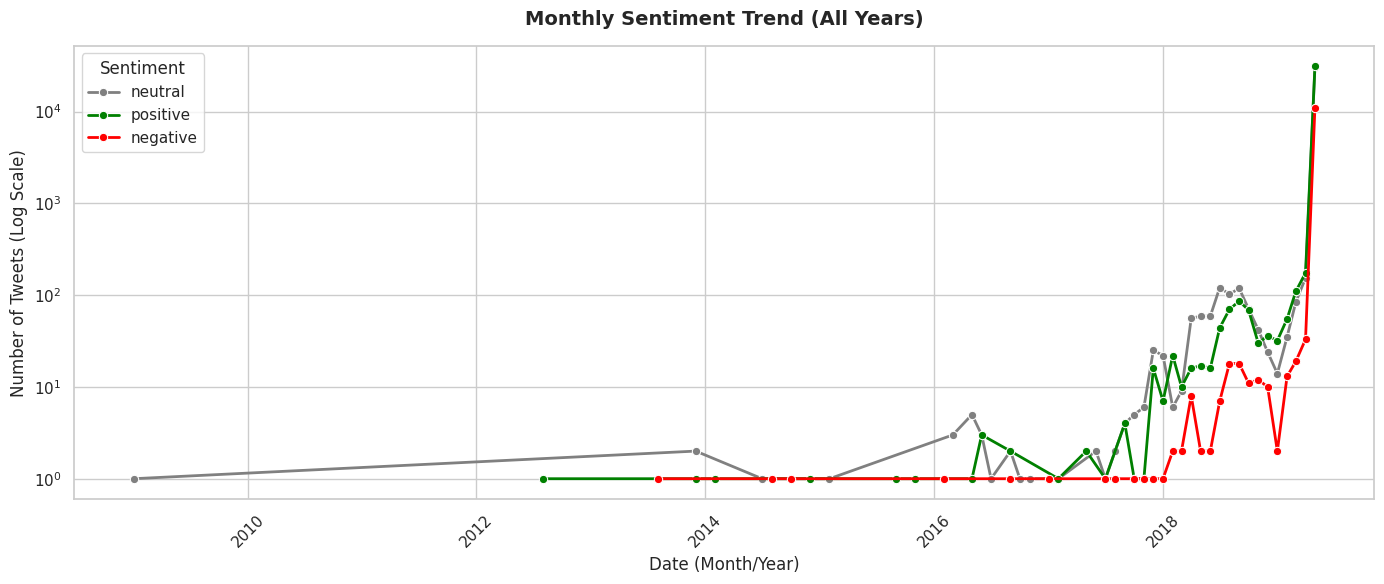

In [ ]:
# Creating the 'month' field.
df_sentiment_monthly = df_sentiment.withColumn(
    "month_date", F.trunc(F.col("date"), "month"))

monthly_all_years = (
    df_sentiment_monthly.groupBy("month_date", "sentiment")
    .agg(F.count("*").alias("count_tweet"))
    .orderBy("month_date"))

pd_monthly_all = monthly_all_years.toPandas()
pd_monthly_all["month_date"] = pd.to_datetime(pd_monthly_all["month_date"])

# Chart.
plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid")

ax1 = sns.lineplot(
    data=pd_monthly_all,
    x="month_date",
    y="count_tweet",
    hue="sentiment",
    palette={"negative": "red", "neutral": "gray", "positive": "green"},
    marker="o",
    linewidth=2)

# Logarithmic scale.
plt.yscale("log")

plt.title("Monthly Sentiment Trend (All Years)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Date (Month/Year)", fontsize=12)
plt.ylabel("Number of Tweets (Log Scale)", fontsize=12)
plt.xticks(rotation=45)
plt.legend(title="Sentiment", frameon=True)
plt.tight_layout()
plt.show()

In [ ]:
# Extract the year from the date.
df_sentiment_year = df_sentiment.withColumn(
    "year",
    F.year(F.col("date")))

# Count tweets for each year.
df_yearly_count = (
    df_sentiment_year
    .groupBy("year")
    .agg(F.count("*").alias("total_tweets"))
    .orderBy("year"))

print("--- Tweet count per year ---")
df_yearly_count.show()

--- Tweet count per year ---
+----+------------+
|year|total_tweets|
+----+------------+
|2009|           1|
|2012|           1|
|2013|           4|
|2014|           5|
|2015|           3|
|2016|          24|
|2017|          79|
|2018|        1206|
|2019|       73236|
+----+------------+



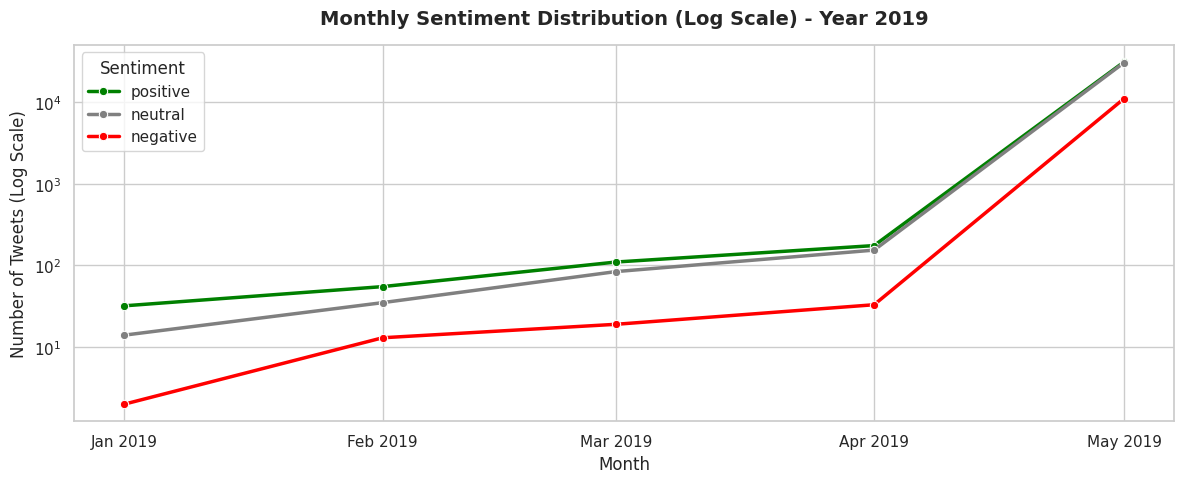

In [ ]:
# Filter for the year 2019 (by month).
monthly_2019 = (
    df_sentiment_monthly.filter(F.year(F.col("date")) == 2019)
    .groupBy("month_date", "sentiment")
    .agg(F.count("*").alias("count_tweet"))
    .orderBy("month_date"))

# Convert to Pandas.
pd_monthly_2019 = monthly_2019.toPandas()
pd_monthly_2019["month_date"] = pd.to_datetime(pd_monthly_2019["month_date"])

# Chart: Focus 2019
plt.figure(figsize=(12, 5))
sns.set_theme(style="whitegrid")

ax2 = sns.lineplot(
    data=pd_monthly_2019,
    x="month_date",
    y="count_tweet",
    hue="sentiment",
    palette={"negative": "red", "neutral": "gray", "positive": "green"},
    marker="o",
    linewidth=2.5)

# Logarithmic scale.
plt.yscale("log")

plt.title("Monthly Sentiment Distribution (Log Scale) - Year 2019", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Tweets (Log Scale)", fontsize=12)

ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax2.xaxis.set_major_locator(mdates.MonthLocator())

plt.xticks(rotation=0)
plt.legend(title="Sentiment", frameon=True)
plt.tight_layout()
plt.show()

## Focus Sentiment Distribution - Peak Period (April - May 2019)

**The chart shows an increase of the number of tweets between April and May. The peak is rappresented by the positive tweets, following by the neutral and the negative ones.**

The research showed that, between 10th and 11th May 2019, the price of Bitcoin increased significantly, reaching \$7,000; compared with a value of less than \$4,000 recorded at the beginning of January of the same year. This increase took place just a few days after the cyberattack on Binance (at the time one of the world’s leading crypto exchanges) which caused the theft of approximately 7,000 BTC.

This context helps to explain the marked concentration of data in 2019. The analysis was therefore limited to this period, in order to ensure the results were more accurate and significant.

**Online source:**
https://www.forbes.com/sites/billybambrough/2019/05/11/bitcoin-just-bounced-to-almost-7000-heres-why/

In [ ]:
# Focus the main temporal analysis on 2019 and
# calculate global engagement metrics by sentiment.
# The analysis focuses on the number of tweets, total engagement,
# average engagement and median engagement.

df_sentiment_filtered = (
    df_sentiment_year
    .filter(F.col("year") == 2019))

df_engagement = (
    df_sentiment_filtered
    .groupBy("sentiment")
    .agg(F.count("*").alias("Total_Tweets"),

        # Likes
        F.sum("likes").alias("Total Likes"),
        F.round(F.avg("likes"), 2).alias("Avg Likes / Tweet"),
        F.expr("percentile_approx(likes, 0.5)").alias("Median Likes"),

        # Replies
        F.sum("replies").alias("Total Replies"),
        F.round(F.avg("replies"), 2).alias("Avg Replies / Tweet"),
        F.expr("percentile_approx(replies, 0.5)").alias("Median Replies"))

    .withColumnRenamed("sentiment", "Sentiment")
    .orderBy("Sentiment"))

print("--- Global engagement metrics by sentiment (2019) ---")
df_engagement.show(truncate=False)


--- Global engagement metrics by sentiment (2019) ---
+---------+------------+-----------+-----------------+------------+-------------+-------------------+--------------+
|Sentiment|Total_Tweets|Total Likes|Avg Likes / Tweet|Median Likes|Total Replies|Avg Replies / Tweet|Median Replies|
+---------+------------+-----------+-----------------+------------+-------------+-------------------+--------------+
|negative |11106       |129481     |11.66            |0           |12601        |1.13               |0             |
|neutral  |30715       |153026     |4.98             |0           |15804        |0.51               |0             |
|positive |31415       |275015     |8.75             |0           |39759        |1.27               |0             |
+---------+------------+-----------+-----------------+------------+-------------+-------------------+--------------+



In [ ]:
# Filter by positive and negative tweets, removing neutral sentiment.
df_positive_negative = (
    df_engagement
    .filter(F.col("Sentiment").isin("positive", "negative"))
    .select(
        "Sentiment",
        "Total_Tweets",
        "Avg Likes / Tweet",
        "Median Likes",
        "Avg Replies / Tweet",
        "Median Replies")
    .orderBy("Sentiment"))

print("--- Positive vs Negative engagement comparison ---")
df_positive_negative.show(truncate=False)

--- Positive vs Negative engagement comparison ---
+---------+------------+-----------------+------------+-------------------+--------------+
|Sentiment|Total_Tweets|Avg Likes / Tweet|Median Likes|Avg Replies / Tweet|Median Replies|
+---------+------------+-----------------+------------+-------------------+--------------+
|negative |11106       |11.66            |0           |1.13               |0             |
|positive |31415       |8.75             |0           |1.27               |0             |
+---------+------------+-----------------+------------+-------------------+--------------+



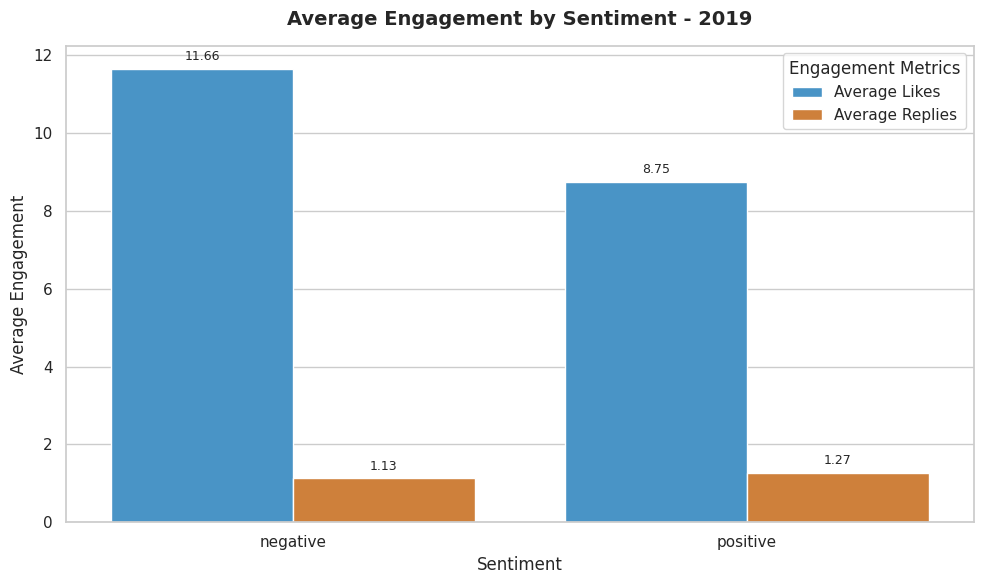

In [ ]:
pd_eng_stats = df_engagement.toPandas()

# Order the sentiment categories.
sentiment_order = ["negative", "positive"]

# Filter to exclude neutral sentiment.
pd_eng_stats = pd_eng_stats[pd_eng_stats["Sentiment"].isin(sentiment_order)]

pd_eng_stats["Sentiment"] = pd.Categorical(
    pd_eng_stats["Sentiment"],
    categories=sentiment_order,
    ordered=True)

pd_eng_stats = pd_eng_stats.sort_values("Sentiment")

# Convert the data to long format for plotting.
pd_melted = pd_eng_stats.melt(
    id_vars=["Sentiment"],
    value_vars=["Avg Likes / Tweet", "Avg Replies / Tweet"],
    var_name="engagement_type",
    value_name="average_count")

pd_melted["engagement_type"] = pd_melted["engagement_type"].map({
    "Avg Likes / Tweet": "Average Likes",
    "Avg Replies / Tweet": "Average Replies"})

# Creating the bar chart.
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=pd_melted,
    x="Sentiment",
    y="average_count",
    hue="engagement_type",
    palette=["#3498db", "#e67e22"],
    order=sentiment_order)

# Add values above each bar.
for p in ax.patches:
    height = p.get_height()

    if height > 0:
        ax.annotate(
            f"{height:.2f}",
            (p.get_x() + p.get_width() / 2, height),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 4),
            textcoords="offset points")

plt.title("Average Engagement by Sentiment - 2019",
    fontsize=14,
    fontweight="bold",
    pad=15)

plt.xlabel("Sentiment", fontsize=12)
plt.ylabel("Average Engagement", fontsize=12)
plt.legend(title="Engagement Metrics", frameon=True)
plt.tight_layout()
plt.show()

## Average Engagement by Sentiment
As shown in the chart, the results indicate an association between the sentiment of tweets and the level of engagement. In particular, **tweets characterised by negative sentiment receive, on average, a higher number of likes**. This may suggest a form of mainly passive participation by users, who respond to the content by liking it – for example, because they agree with it, find it interesting or implicitly express their agreement.

On the other hand, **tweets with positive sentiment receive, on average, a higher number of replies**, suggesting a more active form of interaction. In this case, users appear to be more inclined to comment and participate directly in the conversation, engaging with the author of the tweet or with other users.

In [ ]:
# Importing the BTC-USD dataset.
btc_url = "https://raw.githubusercontent.com/Profession-AI/progetti-big-data/refs/heads/main/Analisi%20del%20consenso%20sul%20Bitcoin/BTC-USD.csv"
local_file_path = "BTC-USD.csv"

# HTTP GET request to the specified URL.
response = requests.get(btc_url)
response.raise_for_status()

with open(local_file_path, "wb") as f:
    # Write the content received from the server to the file.
    f.write(response.content)

# Read the CSV file with Spark.
df_btc_raw = spark.read.csv(
    local_file_path,
    header=True,
    inferSchema=True)

print("--- BTC dataset schema ---")
df_btc_raw.printSchema()

--- BTC dataset schema ---
root
 |-- Date: timestamp (nullable = true)
 |-- Open: double (nullable = true)
 |-- High: double (nullable = true)
 |-- Low: double (nullable = true)
 |-- Close: double (nullable = true)
 |-- Volume: long (nullable = true)
 |-- Dividends: double (nullable = true)
 |-- Stock Splits: double (nullable = true)



In [ ]:
# Convert the 'date' column to a Spark date and the 'Close' column to double.
df_btc_clean = (
    df_btc_raw
    .withColumn("date", F.to_date(F.col("Date")))
    .withColumn("btc_close", F.col("Close").cast("double")))

# Consider only 2019.
df_btc_2019 = (
    df_btc_clean
    .filter(F.year(F.col("date")) == 2019)
    .select("date", "btc_close")
    .orderBy("date"))

print("--- BTC 2019 data ---")
df_btc_2019.show(5)

--- BTC 2019 data ---
+----------+-----------------+
|      date|        btc_close|
+----------+-----------------+
|2019-01-01| 3843.52001953125|
|2019-01-02|3943.409423828125|
|2019-01-03|  3836.7412109375|
|2019-01-04|3857.717529296875|
|2019-01-05|3845.194580078125|
+----------+-----------------+
only showing top 5 rows


In [ ]:
# Calculate the number of positive, negative and neutral tweets for each day.
daily_sentiment_sum = (df_sentiment_filtered
    .groupBy("date")
    .agg(F.count(F.when(F.col("sentiment") == "positive", 1)).alias("pos_count"),
        F.count(F.when(F.col("sentiment") == "negative", 1)).alias("neg_count"),
        F.count(F.when(F.col("sentiment") == "neutral", 1)).alias("neu_count"),
        F.count("*").alias("total_tweets"))
    .orderBy("date"))

print("--- Daily sentiment data ---")
daily_sentiment_sum.show(5)

--- Daily sentiment data ---
+----------+---------+---------+---------+------------+
|      date|pos_count|neg_count|neu_count|total_tweets|
+----------+---------+---------+---------+------------+
|2019-01-01|        1|        0|        1|           2|
|2019-01-02|        1|        0|        2|           3|
|2019-01-04|        1|        0|        1|           2|
|2019-01-05|        2|        0|        1|           3|
|2019-01-08|        3|        0|        1|           4|
+----------+---------+---------+---------+------------+
only showing top 5 rows


In [ ]:
# Convert to Pandas.
pd_sentiment = daily_sentiment_sum.toPandas()
pd_btc = df_btc_2019.toPandas()

# Standardise date format.
pd_sentiment["date"] = pd.to_datetime(pd_sentiment["date"])
pd_btc["date"] = pd.to_datetime(pd_btc["date"])

# Check temporal coverage.
print("Tweet dates:",
    pd_sentiment["date"].min().date(),
    "to",
    pd_sentiment["date"].max().date())

print("BTC dates:",
    pd_btc["date"].min().date(),
    "to",
    pd_btc["date"].max().date())

print("Number of tweet days:", len(pd_sentiment))
print("Number of BTC days:", len(pd_btc))

# Merge sentiment and Bitcoin price.
# Keep only dates available in both datasets.
pd_merged = (
    pd.merge(
        pd_sentiment,
        pd_btc,
        on="date",
        how="inner")
    .sort_values("date")
    .reset_index(drop=True))

print("Number of common days:", len(pd_merged))

print("Common period:",
    pd_merged["date"].min().date(),
    "to",
    pd_merged["date"].max().date())

Tweet dates: 2019-01-01 to 2019-05-27
BTC dates: 2019-01-01 to 2019-12-31
Number of tweet days: 141
Number of BTC days: 365
Number of common days: 141
Common period: 2019-01-01 to 2019-05-27


In [ ]:
# Net Sentiment Index:
# (Positive Tweets - Negative Tweets) / Total Tweets
#
# The index ranges is from -1 to +1.
# Positive values indicate a prevalence of positive tweets,
# while negative values indicate a prevalence of negative tweets.

pd_merged["net_sentiment"] = (
    pd_merged["pos_count"] - pd_merged["neg_count"]
) / pd_merged["total_tweets"]

# Calculate the day-to-day change in the Net Sentiment Index.
pd_merged["sentiment_change"] = (
    pd_merged["net_sentiment"].diff())

# Calculate the daily percentage return of Bitcoin.
pd_merged["btc_return_pct"] = (
    pd_merged["btc_close"].pct_change() * 100)

# Remove the first row (NaN value resulting from the lag shift).
pd_analysis = pd_merged.dropna(
    subset=["sentiment_change", "btc_return_pct"]).copy()

print("Number of observations used in correlation analysis:",
      len(pd_analysis))

Number of observations used in correlation analysis: 140


In [ ]:
# Correlation matrix.
correlation_matrix = pd_analysis[
    ["btc_return_pct",
     "sentiment_change",
     "net_sentiment",
     "total_tweets"]
].corr()

In [ ]:
# Pearson correlation.
sentiment_btc_corr = (
    pd_analysis["btc_return_pct"]
    .corr(pd_analysis["sentiment_change"]))

print("Correlation between Bitcoin daily returns and sentiment changes:",f"{sentiment_btc_corr:.4f}")

Correlation between Bitcoin daily returns and sentiment changes: 0.0512


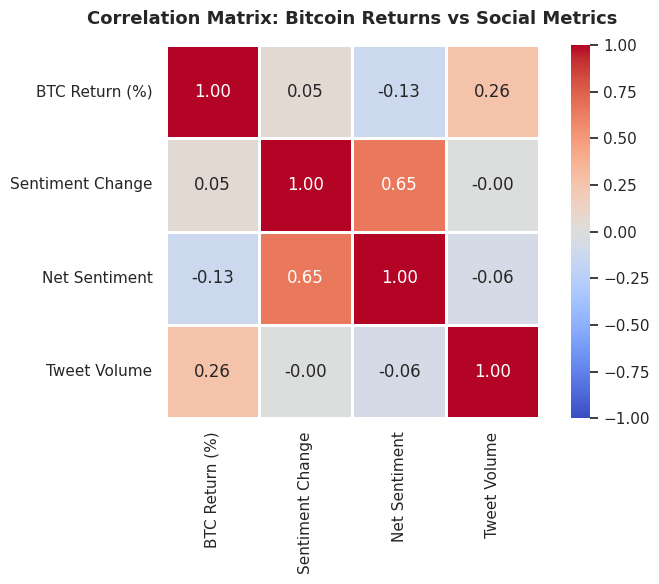

In [ ]:
# Creating the heatmap.
plt.figure(figsize=(8, 6))
sns.set_theme(style="white")

# Rename the variables for the graph.
corr_readable = correlation_matrix.rename(
    columns={
        "btc_return_pct": "BTC Return (%)",
        "sentiment_change": "Sentiment Change",
        "net_sentiment": "Net Sentiment",
        "total_tweets": "Tweet Volume"},
    index={
        "btc_return_pct": "BTC Return (%)",
        "sentiment_change": "Sentiment Change",
        "net_sentiment": "Net Sentiment",
        "total_tweets": "Tweet Volume"})

sns.heatmap(
    corr_readable,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",     # Red = Positive, Blue = Negative
    vmin=-1, vmax=1,     # Standard Pearson scale [-1, 1]
    linewidths=1,
    square=True)

plt.title("Correlation Matrix: Bitcoin Returns vs Social Metrics", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

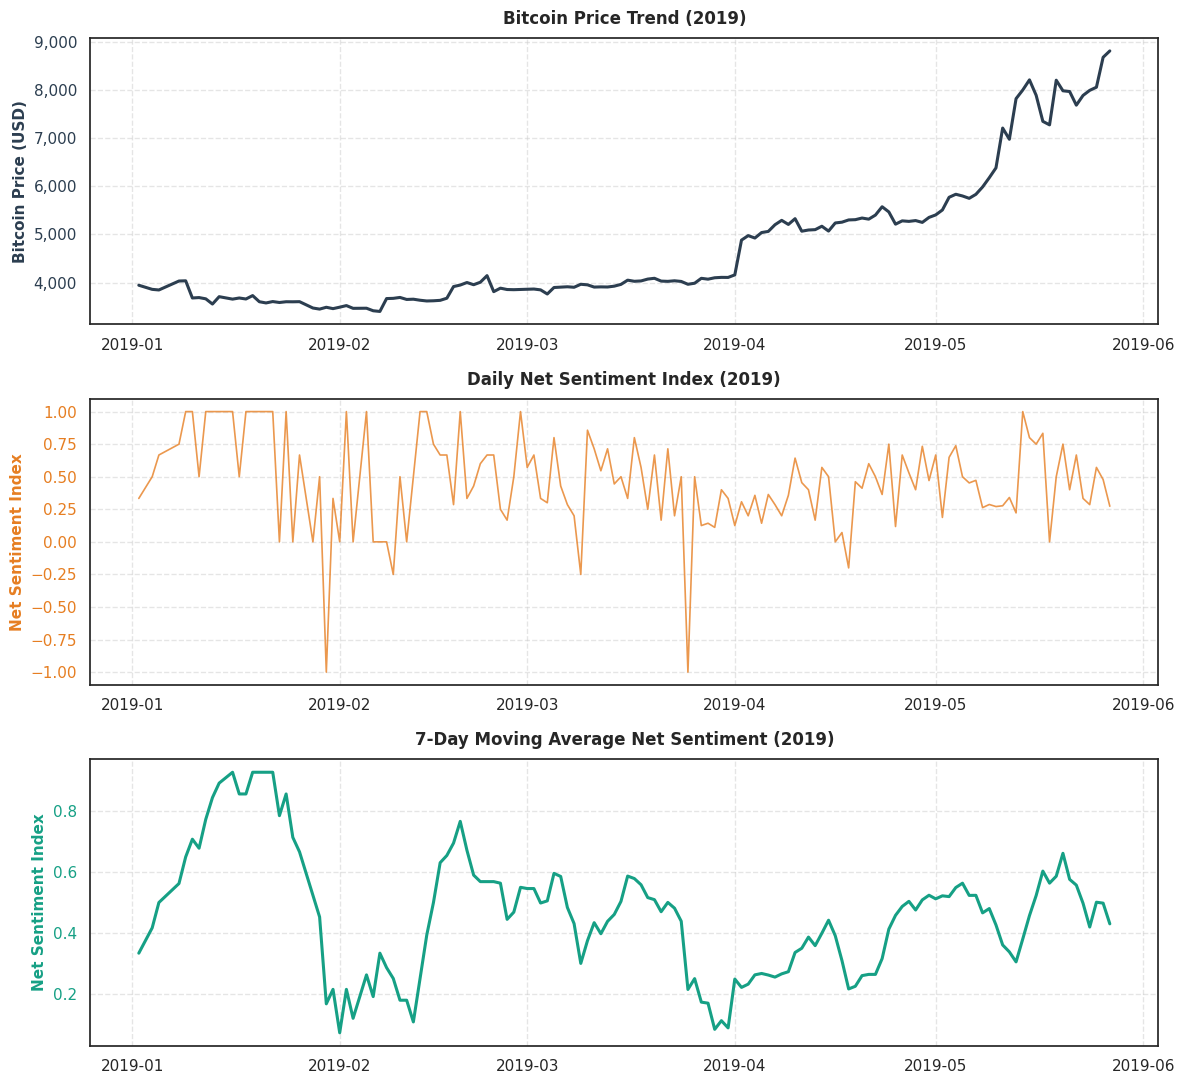

In [ ]:
# Bitcoin Price Vs. Sentiment Trend.

# Calculate the 7-day moving average of Net Sentiment.
pd_analysis["net_sentiment_7d"] = pd_analysis["net_sentiment"].rolling(window=7, min_periods=1).mean()

# Creating three charts.
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 11), sharex=False)
sns.set_theme(style="whitegrid")

# Chart 1: Bitcoin price.
color_btc = "#2c3e50"
ax1.plot(
    pd_analysis["date"],
    pd_analysis["btc_close"],
    color=color_btc,
    linewidth=2.2,
    label="BTC Price")

ax1.set_ylabel("Bitcoin Price (USD)", color=color_btc, fontsize=11, fontweight="bold")
ax1.tick_params(axis="y", labelcolor=color_btc)
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax1.set_title("Bitcoin Price Trend (2019)", fontsize=12, fontweight="bold", pad=10)
ax1.grid(True, linestyle="--", alpha=0.5)

# Chart 2: Daily Net Sentiment.
color_sent = "#e67e22"
ax2.plot(
    pd_analysis["date"],
    pd_analysis["net_sentiment"],
    color=color_sent,
    linewidth=1.2,
    alpha=0.8,
    label="Net Sentiment (Daily)")

ax2.set_ylabel("Net Sentiment Index", color=color_sent, fontsize=11, fontweight="bold")
ax2.tick_params(axis="y", labelcolor=color_sent)
ax2.set_title("Daily Net Sentiment Index (2019)", fontsize=12, fontweight="bold", pad=10)
ax2.grid(True, linestyle="--", alpha=0.5)

# Chart 3: Net Sentiment (7-Day Moving Average).
color_sent = "#16a085"
ax3.plot(
    pd_analysis["date"],
    pd_analysis["net_sentiment_7d"],
    color=color_sent,
    linewidth=2.2,
    linestyle="-",
    label="Net Sentiment (7D Avg)")

ax3.set_ylabel("Net Sentiment Index", color=color_sent, fontsize=11, fontweight="bold")
ax3.tick_params(axis="y", labelcolor=color_sent)
ax3.set_title("7-Day Moving Average Net Sentiment (2019)", fontsize=12, fontweight="bold", pad=10)
ax3.grid(True, linestyle="--", alpha=0.5)

fig.tight_layout()
plt.show()

## Chart 1: Bitcoin Price Trend

The chart shows the trend in the price of Bitcoin between January and May. From January to April, the price remained relatively stable, while between April and May there was a significant increase, passing from around \$4,000 to \$7,000.

## Chart 2: Daily Net Sentiment Index

The chart shows the evolution of sentiment over the year, which was generally positive, although there were brief periods characterised by strong pessimism. Unlike the price of Bitcoin, sentiment did not follow a consistent growing trend but fluctuated over time.

## Chart 3: 7-Day Moving Average Net Sentiment

 The chart shows the moving average of sentiment, introduced to reduce the noise caused by daily volatility and to clarify the trend’s evolution over the course of the year. Despite daily fluctuations, average sentiment remains generally positive. However, its trend varies over time: following an initial phase of optimism, a downturn is observed between February and March, followed by a recovery in April and May.

# Conclusions:

A comparison of the charts shows that the price of Bitcoin and sentiment do not always follow the same trend. In the early months of the period analysed, sentiment remained positive even when the price was stable or falling.
Furthermore, the rapid increase in the price of Bitcoin between April and May has not been followed by an equally marked improvement in average sentiment. While the price has increased by a significant amount over a short period of time, sentiment has improved more gradually and moderately.

**Overall, these results suggest that the relationship between the price of Bitcoin and sentiment is not necessarily direct or linear**: the two indicators may exhibit different behaviours and respond with different intensities to market fluctuations.


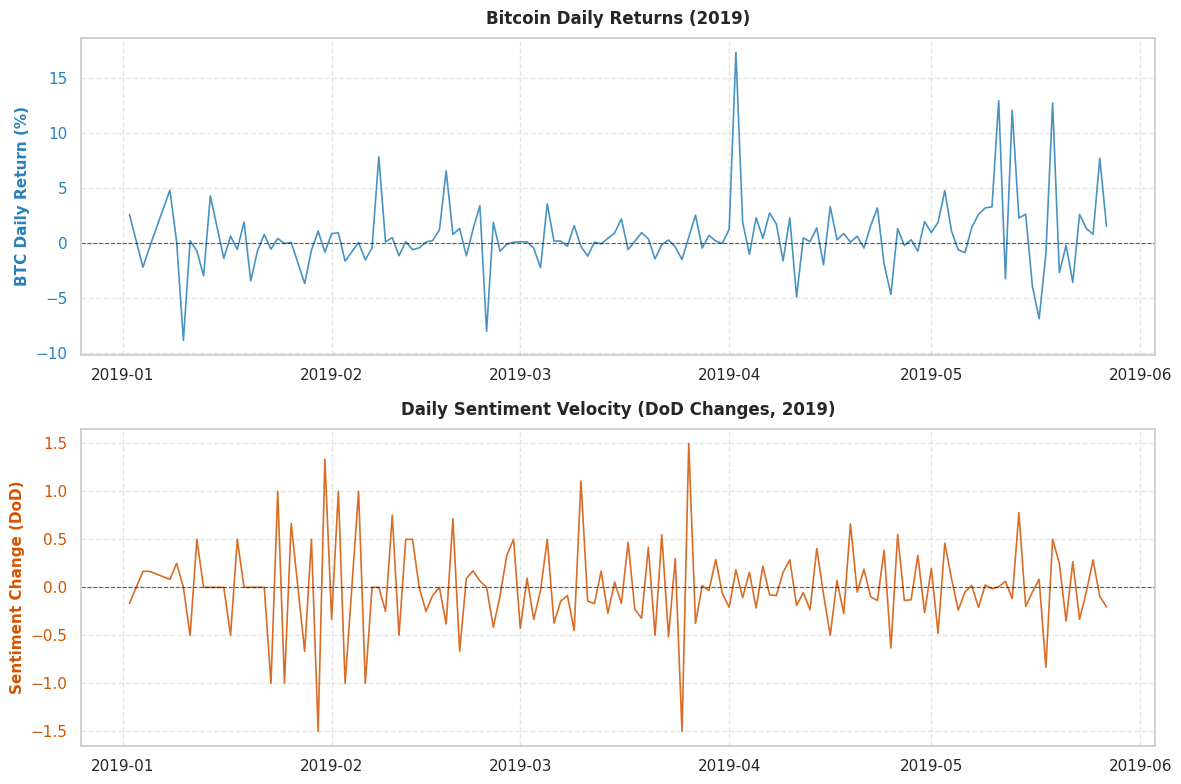

In [ ]:
# Daily Bitcoin Returns vs. Sentiment Changes.

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=False)
sns.set_theme(style="whitegrid")

# Chart 1: Bitcoin Daily Return (%).
color_btc = "#2980b9"
ax1.plot(
    pd_analysis["date"],
    pd_analysis["btc_return_pct"],
    color=color_btc,
    linewidth=1.2,
    alpha=0.85,
    label="BTC Return (%)")

ax1.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.6)
ax1.set_ylabel("BTC Daily Return (%)", color=color_btc, fontsize=11, fontweight="bold")
ax1.tick_params(axis="y", labelcolor=color_btc)
ax1.set_title("Bitcoin Daily Returns (2019)", fontsize=12, fontweight="bold", pad=10)
ax1.grid(True, linestyle="--", alpha=0.5)

# Chart 2: Daily Sentiment Change (DoD).
color_sent = "#d35400"
ax2.plot(
    pd_analysis["date"],
    pd_analysis["sentiment_change"],
    color=color_sent,
    linewidth=1.2,
    alpha=0.85,
    label="Sentiment Velocity")

ax2.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.6)
ax2.set_ylabel("Sentiment Change (DoD)", color=color_sent, fontsize=11, fontweight="bold")
ax2.tick_params(axis="y", labelcolor=color_sent)
ax2.set_title("Daily Sentiment Velocity (DoD Changes, 2019)", fontsize=12, fontweight="bold", pad=10)
ax2.grid(True, linestyle="--", alpha=0.5)

fig.tight_layout()
plt.show()

## Chart 1: Bitcoin Daily Returns

The chart, we can see how Bitcoin’s daily returns, over the period from January to May 2019, fluctuated mainly around zero, although there were some peaks, both positive and negative. Days were characterised by periods of relatively low volatility and episodes of significant instability, highlighting the market’s volatility.

## Chart 2: Daily Sentiment Velocity

The chart, on the other hand, analyses the daily variation in sentiment. As can be seen, there were significant fluctuations at the beginning of the year, both positive and negative, while in the following months the fluctuations generally appeared more moderate, although there were still some peaks. This alternation between positive and negative variations indicates that sentiment has changed over time, without showing a clear direction.

In [ ]:
# Lead-Lag Analysis.

# Sort the dates in chronological order.
pd_analysis = (pd_analysis.sort_values("date").reset_index(drop=True))

# Create a date-indexed dataset.
pd_lag = (pd_analysis[["date", "sentiment_change", "btc_return_pct"]]
    .set_index("date")
    .sort_index())

print("--- Date coverage ---")
print("From:",pd_lag.index.min().date())
print("To:",pd_lag.index.max().date())
print("Number of observations:",len(pd_lag))

--- Date coverage ---
From: 2019-01-02
To: 2019-05-27
Number of observations: 140


In [ ]:
# Calculate lagged correlations.
lag_results = []

for lag in range(-5, 6):

    if lag < 0:

        # Negative lag: sentiment LEADS Bitcoin.
        sentiment_series = (pd_lag["sentiment_change"].shift(-lag, freq="D"))
        btc_series = (pd_lag["btc_return_pct"])

        interpretation = (f"Sentiment leads BTC by {abs(lag)} day(s)")

    elif lag > 0:

        # Positive lag: Bitcoin LEADS sentiment.
        sentiment_series = (pd_lag["sentiment_change"])
        btc_series = (pd_lag["btc_return_pct"].shift(lag, freq="D"))
        interpretation = (f"BTC leads sentiment by {lag} day(s)")

    else:

        # Lag 0: same day.
        sentiment_series = (pd_lag["sentiment_change"])
        btc_series = (pd_lag["btc_return_pct"])
        interpretation = "Same day"

    # Sort the two series by date.
    valid_data = pd.concat(
        [sentiment_series.rename("sentiment"),btc_series.rename("btc_return")],
        axis=1).dropna()

    # Calculate Pearson’s correlation coefficient and the p-value.
    correlation, p_value = pearsonr(
        valid_data["sentiment"],
        valid_data["btc_return"])

    lag_results.append({
        "lag": lag,
        "correlation": correlation,
        "p_value": p_value,
        "observations": len(valid_data),
        "interpretation": interpretation})

# Print the results as a DataFrame.
lag_results = pd.DataFrame(lag_results)
print("--- Lagged Correlation Analysis ---\n")
print(lag_results.to_string(index=False))

--- Lagged Correlation Analysis ---

 lag  correlation  p_value  observations                  interpretation
  -5    -0.065616 0.456506           131 Sentiment leads BTC by 5 day(s)
  -4     0.060495 0.490786           132 Sentiment leads BTC by 4 day(s)
  -3     0.007897 0.928120           133 Sentiment leads BTC by 3 day(s)
  -2    -0.094009 0.281788           133 Sentiment leads BTC by 2 day(s)
  -1    -0.070105 0.420873           134 Sentiment leads BTC by 1 day(s)
   0     0.051234 0.547729           140                        Same day
   1     0.136885 0.114761           134 BTC leads sentiment by 1 day(s)
   2    -0.063303 0.469136           133 BTC leads sentiment by 2 day(s)
   3    -0.000828 0.992456           133 BTC leads sentiment by 3 day(s)
   4     0.014718 0.866975           132 BTC leads sentiment by 4 day(s)
   5     0.009990 0.909832           131 BTC leads sentiment by 5 day(s)


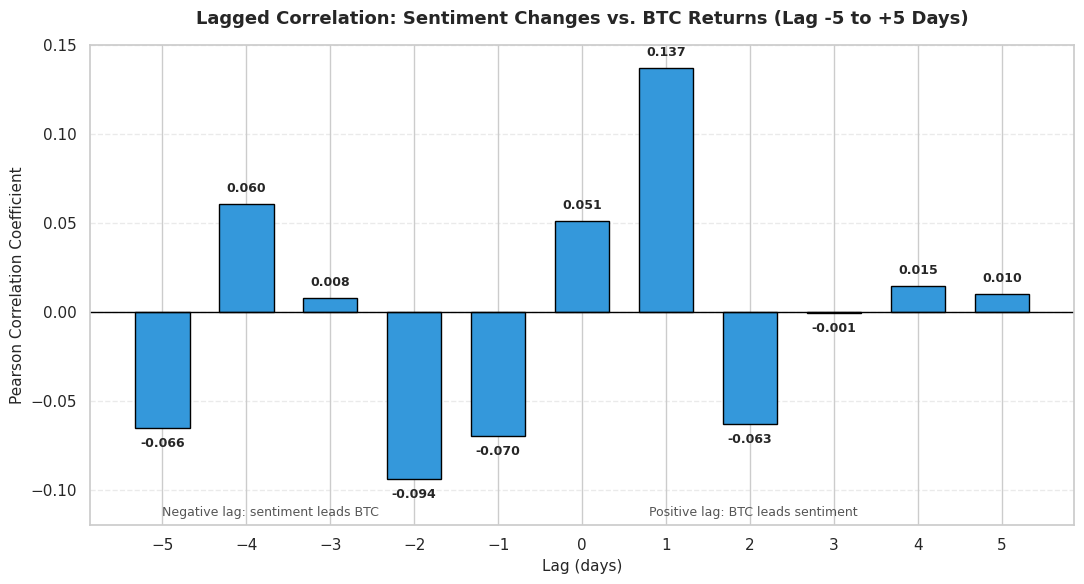

In [ ]:
# Creating the chart.
plt.figure(figsize=(11, 6))

bars = plt.bar(
    lag_results["lag"],
    lag_results["correlation"],
    color="#3498db",
    edgecolor="black",
    width=0.65)

# Zero line.
plt.axhline(0,color="black",linewidth=1)

# Add correlation values.
for bar in bars:

    height = bar.get_height()

    if height >= 0:
        y_position = height + 0.005
        vertical_alignment = "bottom"
    else:
        y_position = height - 0.005
        vertical_alignment = "top"

    plt.annotate(
        f"{height:.3f}",
        (bar.get_x() + bar.get_width() / 2, y_position),
        ha="center",
        va=vertical_alignment,
        fontsize=9,
        fontweight="bold")

plt.title(
    "Lagged Correlation: Sentiment Changes vs. BTC Returns (Lag -5 to +5 Days)",
    fontsize=13,
    fontweight="bold",
    pad=15)

plt.xlabel("Lag (days)",fontsize=11)
plt.ylabel("Pearson Correlation Coefficient",fontsize=11)

# Explain the lag convention.
plt.text(
    -5,
    -0.115,
    "Negative lag: sentiment leads BTC",
    fontsize=9,
    color="#555555")

plt.text(
    0.8,
    -0.115,
    "Positive lag: BTC leads sentiment",
    fontsize=9,
    color="#555555")

plt.ylim(-0.12, 0.15)
plt.xticks(range(-5, 6))
plt.grid(axis="y",linestyle="--",alpha=0.4)
plt.tight_layout()
plt.show()

## Lagged Correlation: Sentiment Changes vs. BTC Returns

**The chart shows no statistically significant relationship between changes in sentiment and Bitcoin’s returns over the ±5-day because the correlation coefficients are close to zero.** The highest positive correlation across the entire interval (r = 0.136) is recorded at lag +1 and the lowest is recorded at lag -2 (r = -0.093).